# Clase 4: entrenamiento supervisado

**Asignatura:** Machine Learning (RIA-805)  
**Dataset:** Crop Recommendation

En la clase anterior preparamos los datos y evitamos la fuga de informacion durante el preprocesamiento. Ahora usaremos esas variables para entrenar y comparar tres clasificadores: Random Forest, XGBoost y SVM.

Al terminar, tendremos modelos evaluados sobre los mismos datos de prueba, compararemos sus metricas y guardaremos los modelos entrenados para reutilizarlos.

## 1. ¿Que es el aprendizaje supervisado?

En el aprendizaje supervisado damos al algoritmo ejemplos con una respuesta conocida. En este dataset:

- **Variables predictoras (`X`):** mediciones del suelo y del clima, como `N`, `P`, `K`, temperatura, humedad, pH y lluvia.
- **Variable objetivo (`y`):** el cultivo indicado en `label`.

El modelo aprende patrones a partir de ejemplos y luego predice la etiqueta para observaciones que no ha visto. Por eso reservaremos una parte de los datos para probarlo al final.

In [10]:
from pathlib import Path
import time

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

# El notebook puede ejecutarse desde la raiz o desde la carpeta notebooks.
project_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data" / "processed" / "crop.parquet").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No se encontro data/processed/crop.parquet desde la carpeta actual."
    )

data_path = project_root / "data" / "processed" / "crop.parquet"
models_dir = project_root / "models"
reports_dir = project_root / "reports"
figures_dir = reports_dir / "figures"
target_column = "label"
random_state = 42

df = pd.read_parquet(data_path)
print(f"Dataset cargado desde: {data_path}")
print(f"Filas y columnas: {df.shape}")
display(df.head())

Dataset cargado desde: c:\Users\marco\ml-demo1-profesor\data\processed\crop.parquet
Filas y columnas: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 2. Revisar los datos y separar `X` e `y`

Antes de entrenar, comprobamos que el archivo contiene las columnas esperadas y que las variables predictoras son numericas. Esta validacion conecta la clase actual con el resultado del preprocesamiento anterior.

`X` contiene la informacion que el modelo puede usar. `y` contiene la respuesta que queremos que aprenda a predecir.

In [11]:
if target_column not in df.columns:
    raise ValueError(f"No existe la columna objetivo '{target_column}'.")
if df.isna().any().any():
    raise ValueError(
        "El dataset contiene valores faltantes. Vuelve a la clase de "
        "preprocesamiento y revisa el tratamiento de NaN."
    )

X = df.drop(columns=target_column)
y = df[target_column].astype(str)

non_numeric_columns = X.select_dtypes(exclude="number").columns.tolist()
if non_numeric_columns:
    raise ValueError(f"Hay predictores no numericos: {non_numeric_columns}")

print(f"Variables predictoras: {X.columns.tolist()}")
print(f"Cantidad de clases de cultivo: {y.nunique()}")
display(y.value_counts().sort_index().rename("observaciones").to_frame())

Variables predictoras: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Cantidad de clases de cultivo: 22


,observaciones
label,
apple,100
banana,100
blackgram,100
chickpea,100
coconut,100
coffee,100
cotton,100
grapes,100
jute,100


## 3. Separar entrenamiento y prueba

No debemos evaluar un modelo con los mismos ejemplos que utilizo para aprender. Separaremos el 80% para entrenamiento y reservaremos el 20% para la prueba final.

Usamos `stratify=y` para que ambos grupos mantengan aproximadamente la misma proporcion de cada cultivo. La semilla fija (`random_state`) permite repetir el ejercicio y obtener la misma particion.

La codificacion de la etiqueta convierte los nombres de cultivos en numeros, requeridos por XGBoost. Primero separamos los datos y el codificador aprende las categorias a partir de las etiquetas de entrenamiento.

In [12]:
X_train, X_test, y_train_text, y_test_text = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=random_state,
    stratify=y,
)

label_encoder = LabelEncoder()
y_train = pd.Series(
    label_encoder.fit_transform(y_train_text), index=y_train_text.index
)
y_test = pd.Series(
    label_encoder.transform(y_test_text), index=y_test_text.index
)

print(f"Filas de entrenamiento: {len(X_train)}")
print(f"Filas de prueba: {len(X_test)}")
print(f"Clases codificadas: {list(label_encoder.classes_)}")

Filas de entrenamiento: 1760
Filas de prueba: 440
Clases codificadas: ['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']


## 4. Los tres modelos

- **Random Forest:** combina muchos arboles de decision entrenados con muestras y variables distintas. Sus votaciones reducen la variabilidad de un arbol individual.
- **XGBoost:** construye arboles en secuencia; cada nuevo arbol intenta corregir errores de los anteriores.
- **SVM:** busca una frontera que separe las clases maximizando el margen. Con el kernel RBF puede representar fronteras no lineales.

Random Forest y XGBoost se basan en divisiones por umbrales, por lo que escalar sus variables no suele ser necesario. SVM utiliza distancias y es sensible a la escala; por eso su `RobustScaler` se ajusta dentro de un `Pipeline`, usando solo el conjunto de entrenamiento.

### Hiperparametros principales

Los hiperparametros se eligen antes del entrenamiento: definen como aprende el algoritmo. No existe una unica combinacion correcta; mas adelante se pueden ajustar con validacion cruzada. En la celda siguiente fijamos una configuracion inicial para comparar los modelos.

| Modelo | Hiperparametro | Valor en esta clase | ¿Que controla? |
|---|---|---:|---|
| Random Forest | `n_estimators` | `200` | Cantidad de arboles que votan. Mas arboles pueden estabilizar el resultado, pero aumentan el tiempo. |
| Random Forest | `max_depth` | Predeterminado (`None`) | Profundidad maxima de cada arbol. Limitarla puede reducir sobreajuste. |
| Random Forest | `max_features` | Predeterminado (`"sqrt"`) | Cantidad de variables consideradas al buscar cada division. |
| Random Forest | `random_state` | `42` | Fija la aleatoriedad para poder repetir el experimento. |
| Random Forest | `n_jobs` | `-1` | Usa todos los nucleos disponibles; afecta el tiempo, no el aprendizaje. |
| XGBoost | `n_estimators` | `200` | Numero de arboles construidos secuencialmente. |
| XGBoost | `max_depth` | `6` | Profundidad maxima de cada arbol; mas profundidad aumenta complejidad. |
| XGBoost | `learning_rate` | `0.1` | Cuanto aporta cada arbol nuevo. Valores bajos suelen requerir mas arboles. |
| XGBoost | `subsample` | `0.9` | Proporcion de filas usada para construir cada arbol; puede ayudar a reducir sobreajuste. |
| XGBoost | `colsample_bytree` | `0.9` | Proporcion de variables usada por cada arbol. |
| XGBoost | `objective` | `"multi:softprob"` | Configura clasificacion multiclase y produce probabilidades por clase. |
| XGBoost | `eval_metric` | `"mlogloss"` | Metrica interna que se calcula durante el entrenamiento para las clases. |
| SVM | `kernel` | `"rbf"` | Permite separar clases con fronteras no lineales. |
| SVM | `C` | Predeterminado (`1.0`) | Balancea margen amplio frente a penalizar errores de entrenamiento. |
| SVM | `gamma` | Predeterminado (`"scale"`) | Controla el alcance de influencia de cada ejemplo con kernel RBF. |
| SVM | `RobustScaler` | Mediana y rango intercuartil | Ajusta la escala de las variables antes del SVM; el `Pipeline` lo aprende solo con train. |

Los parametros no indicados conservan los valores predeterminados de la biblioteca. `random_state` y `n_jobs` son utiles para reproducibilidad y velocidad, aunque no describen directamente la complejidad del modelo.

In [13]:
modelos = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=random_state,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=random_state,
        n_jobs=-1,
    ),
    "SVM": Pipeline(
        steps=[
            ("escalador", RobustScaler()),
            ("clasificador", SVC(kernel="rbf")),
        ]
    ),
}

print(f"Modelos que compararemos: {list(modelos)}")

Modelos que compararemos: ['Random Forest', 'XGBoost', 'SVM']


## 5. Entrenar y medir

Entrenaremos cada modelo con exactamente los mismos datos y evaluaremos sus predicciones sobre el mismo conjunto de prueba. Asi la comparacion es justa.

Calcularemos:

- **Accuracy:** proporcion total de predicciones correctas.
- **Precision ponderada:** de las predicciones de cada cultivo, cuantas fueron correctas, combinando las clases segun su cantidad de ejemplos.
- **Recall ponderado:** de los ejemplos reales de cada cultivo, cuantos encontro el modelo, tambien ponderado por clase.
- **F1 ponderado:** equilibrio entre precision y recall.
- **Tiempo:** duracion de entrenamiento y de prediccion. Los tiempos dependen del equipo y no son una medida de calidad por si solos.

In [14]:
resultados = []
predicciones = {}

for nombre, modelo in modelos.items():
    print(f"Entrenando {nombre}...")

    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tiempo_entrenamiento = time.perf_counter() - inicio

    inicio = time.perf_counter()
    y_pred = modelo.predict(X_test)
    tiempo_inferencia = time.perf_counter() - inicio
    predicciones[nombre] = y_pred

    resultados.append(
        {
            "modelo": nombre,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision_weighted": precision_score(
                y_test, y_pred, average="weighted", zero_division=0
            ),
            "recall_weighted": recall_score(
                y_test, y_pred, average="weighted", zero_division=0
            ),
            "f1_weighted": f1_score(
                y_test, y_pred, average="weighted", zero_division=0
            ),
            "tiempo_entrenamiento_s": tiempo_entrenamiento,
            "tiempo_inferencia_s": tiempo_inferencia,
        }
    )
    print(f"  Accuracy: {resultados[-1]['accuracy']:.4f}")
    print(f"  F1 ponderado: {resultados[-1]['f1_weighted']:.4f}")

resultados_df = pd.DataFrame(resultados)

Entrenando Random Forest...
  Accuracy: 0.9955
  F1 ponderado: 0.9955
Entrenando XGBoost...
  Accuracy: 0.9909
  F1 ponderado: 0.9908
Entrenando SVM...
  Accuracy: 0.9841
  F1 ponderado: 0.9840


## 6. Comparar los resultados

La tabla permite comparar los indicadores lado a lado. Ninguna metrica cuenta toda la historia: accuracy resume los aciertos globales, mientras que precision, recall y F1 ayudan a analizar distintos tipos de error.

El grafico resume accuracy, F1 ponderado y tiempo de entrenamiento. Observa que diferencias pequenas en rendimiento pueden tener costos de tiempo distintos.

,modelo,accuracy,precision_weighted,recall_weighted,f1_weighted,tiempo_entrenamiento_s,tiempo_inferencia_s
0,Random Forest,0.9955,0.9957,0.9955,0.9955,0.336,0.051
1,XGBoost,0.9909,0.9915,0.9909,0.9908,1.039,0.008
2,SVM,0.9841,0.9859,0.9841,0.9840,0.039,0.046


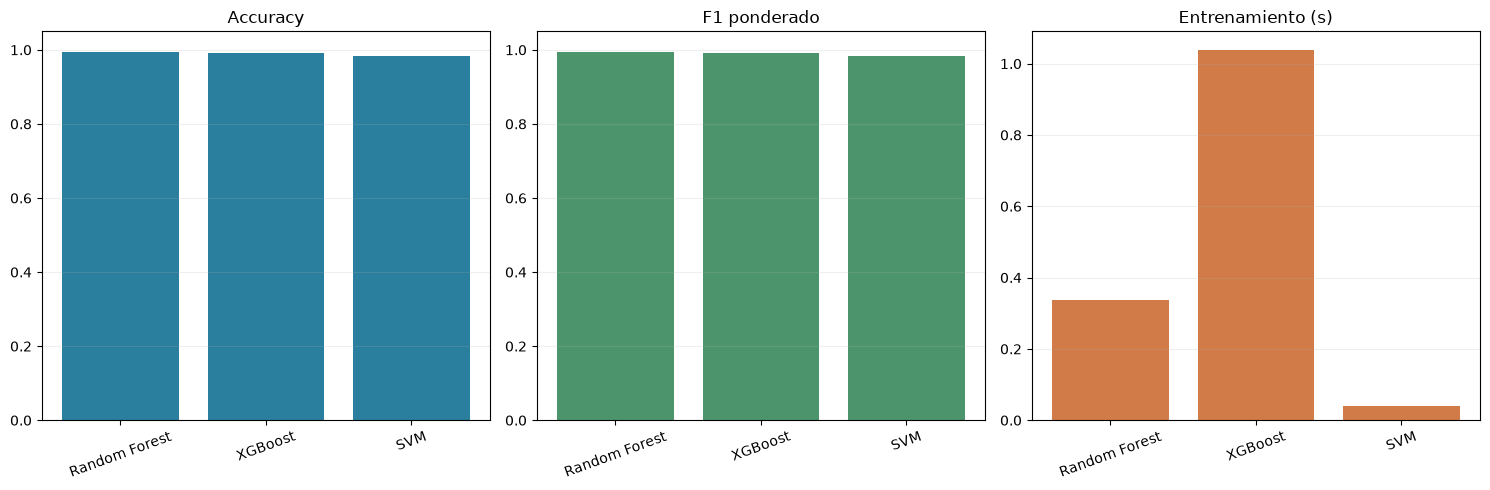

In [15]:
display(
    resultados_df.sort_values("f1_weighted", ascending=False).style.format(
        {
            "accuracy": "{:.4f}",
            "precision_weighted": "{:.4f}",
            "recall_weighted": "{:.4f}",
            "f1_weighted": "{:.4f}",
            "tiempo_entrenamiento_s": "{:.3f}",
            "tiempo_inferencia_s": "{:.3f}",
        }
    )
)

figura, ejes = plt.subplots(1, 3, figsize=(15, 5))
metricas = [
    ("accuracy", "Accuracy", "#2a7f9e"),
    ("f1_weighted", "F1 ponderado", "#4c956c"),
    ("tiempo_entrenamiento_s", "Entrenamiento (s)", "#d17b49"),
]
for eje, (columna, titulo, color) in zip(ejes, metricas):
    eje.bar(resultados_df["modelo"], resultados_df[columna], color=color)
    eje.set_title(titulo)
    eje.tick_params(axis="x", labelrotation=20)
    if columna != "tiempo_entrenamiento_s":
        eje.set_ylim(0, 1.05)
    eje.grid(axis="y", alpha=0.2)

figura.tight_layout()
plt.show()

## 7. Importancia de variables para explicar Random Forest

Random Forest permite estimar que variables fueron mas utiles para separar las clases durante el entrenamiento. Esta es una explicacion **global** del modelo: resume su comportamiento para el conjunto de datos, no explica por que se eligio un cultivo para una observacion individual.

Una importancia alta indica que la variable ayudo mucho a las divisiones de los arboles. No significa que esa variable cause el resultado. Si dos variables estan relacionadas, pueden repartirse la importancia; ademas, esta medida basada en impureza puede favorecer variables con muchos valores posibles.

**Lectura para negocio:** el grafico ayuda a priorizar que mediciones revisar, mejorar o comunicar. Antes de convertirlo en una regla o una inversion, hay que contrastarlo con conocimiento del dominio, datos nuevos y el impacto real de la decision. Para una interpretacion mas robusta tambien se puede comparar con permutation importance sobre datos de prueba.

,variable,importancia
0,rainfall,0.220
1,humidity,0.217
2,K,0.181
3,P,0.151
4,N,0.103
5,temperature,0.075
6,ph,0.052


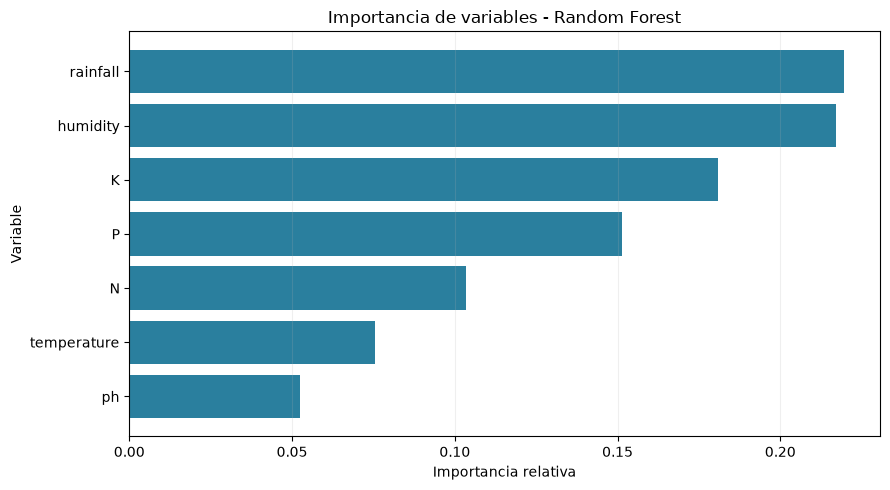

Grafico guardado en: reports\figures\importancia_variables_random_forest.png


In [19]:
rf_model = modelos["Random Forest"]

importancia_features = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns,
    name="importancia",
).sort_values(ascending=False)

importancia_df = importancia_features.rename_axis("variable").reset_index()
display(importancia_df.style.format({"importancia": "{:.3f}"}))

figures_dir.mkdir(parents=True, exist_ok=True)
figura, eje = plt.subplots(figsize=(9, 5))
eje.barh(
    importancia_features.sort_values().index,
    importancia_features.sort_values().values,
    color="#2a7f9e",
)
eje.set_title("Importancia de variables - Random Forest")
eje.set_xlabel("Importancia relativa")
eje.set_ylabel("Variable")
eje.grid(axis="x", alpha=0.2)
figura.tight_layout()

importance_path = figures_dir / "importancia_variables_random_forest.png"
figura.savefig(importance_path, dpi=120)
plt.show()
plt.close(figura)
print(f"Grafico guardado en: {importance_path.relative_to(project_root)}")

## 8. Matrices de confusion

La matriz de confusion separa los aciertos y errores por clase. Las filas representan el cultivo real y las columnas el cultivo predicho; la diagonal principal contiene los aciertos. Los valores fuera de la diagonal muestran que cultivos confunde el modelo.

Como hay 22 cultivos, la matriz es amplia. Busca primero los valores fuera de la diagonal para identificar pares que merezcan analisis.

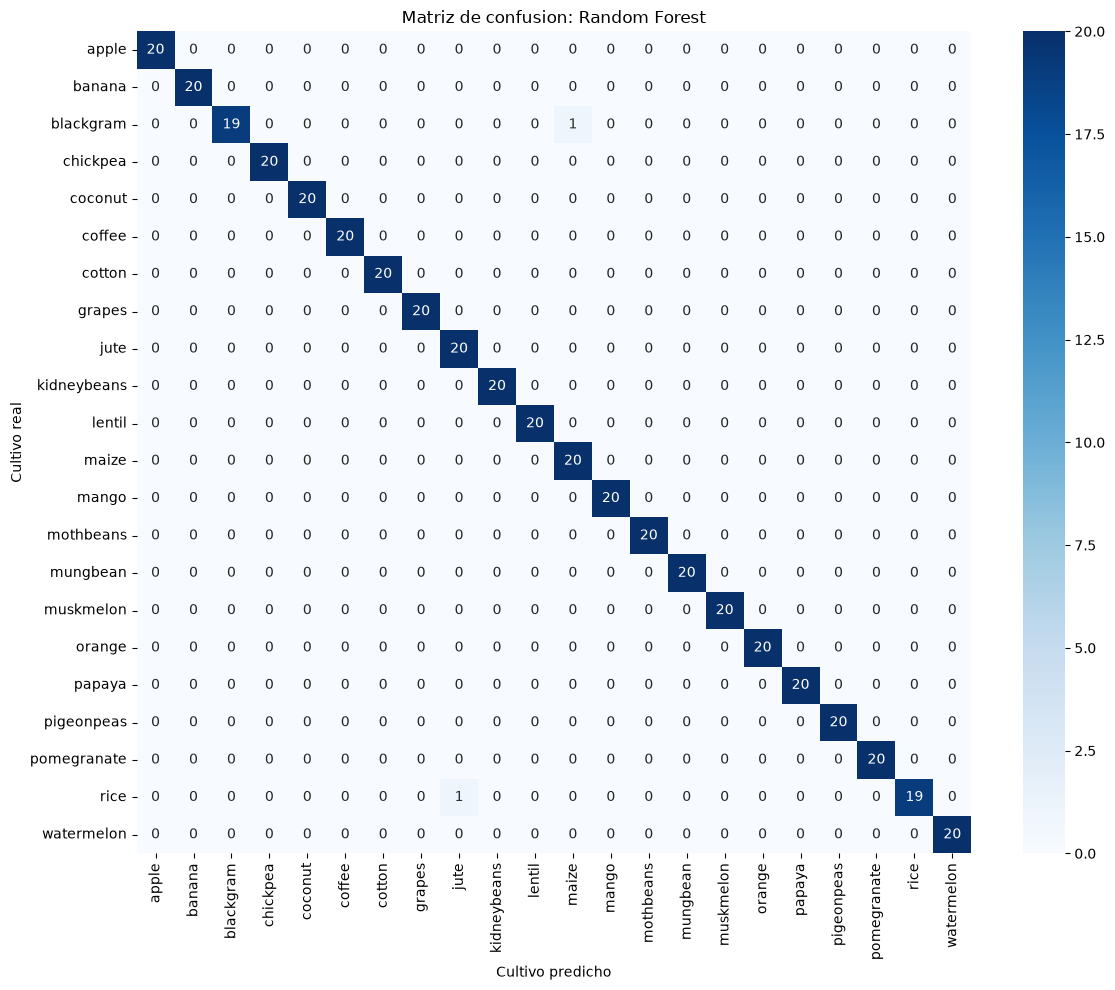

Guardada en: reports\figures\matriz_confusion_random_forest.png


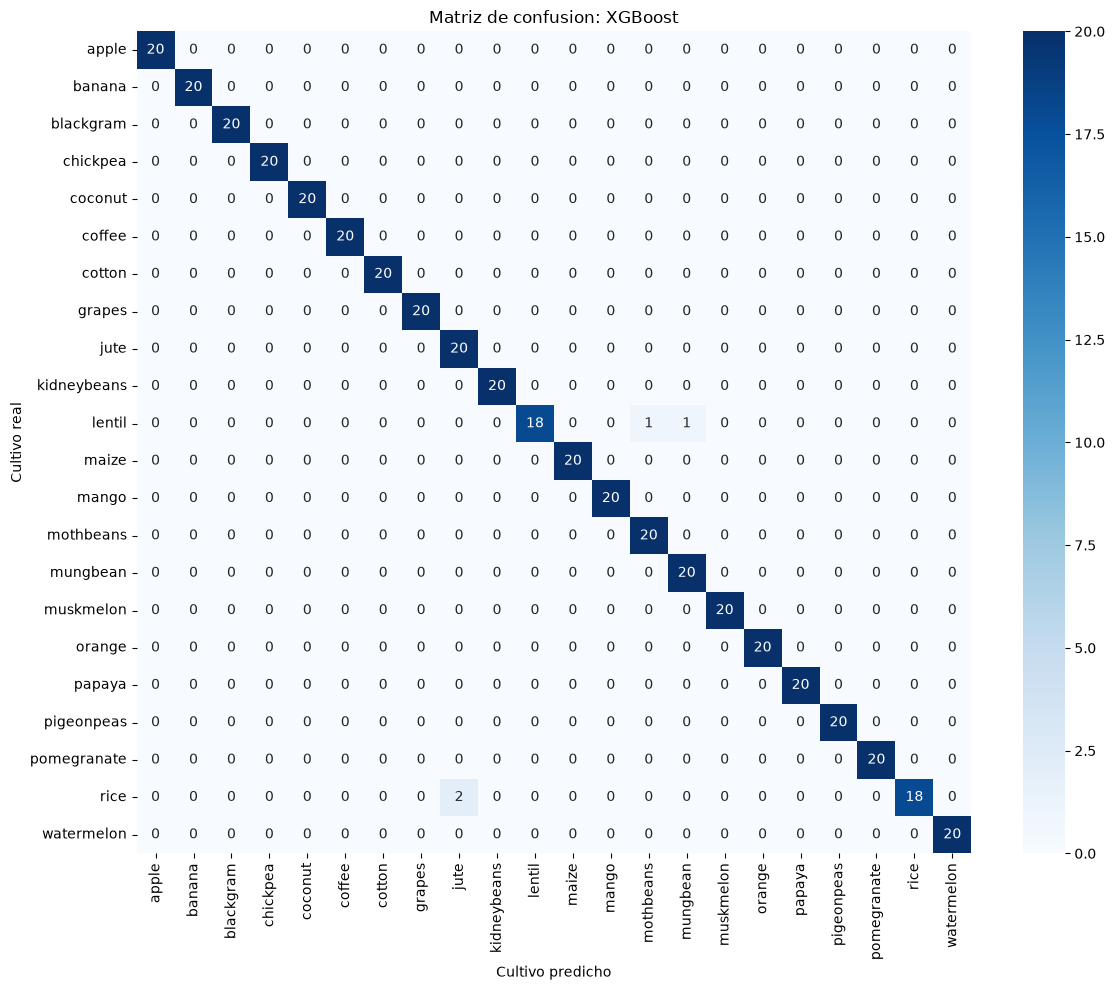

Guardada en: reports\figures\matriz_confusion_xgboost.png


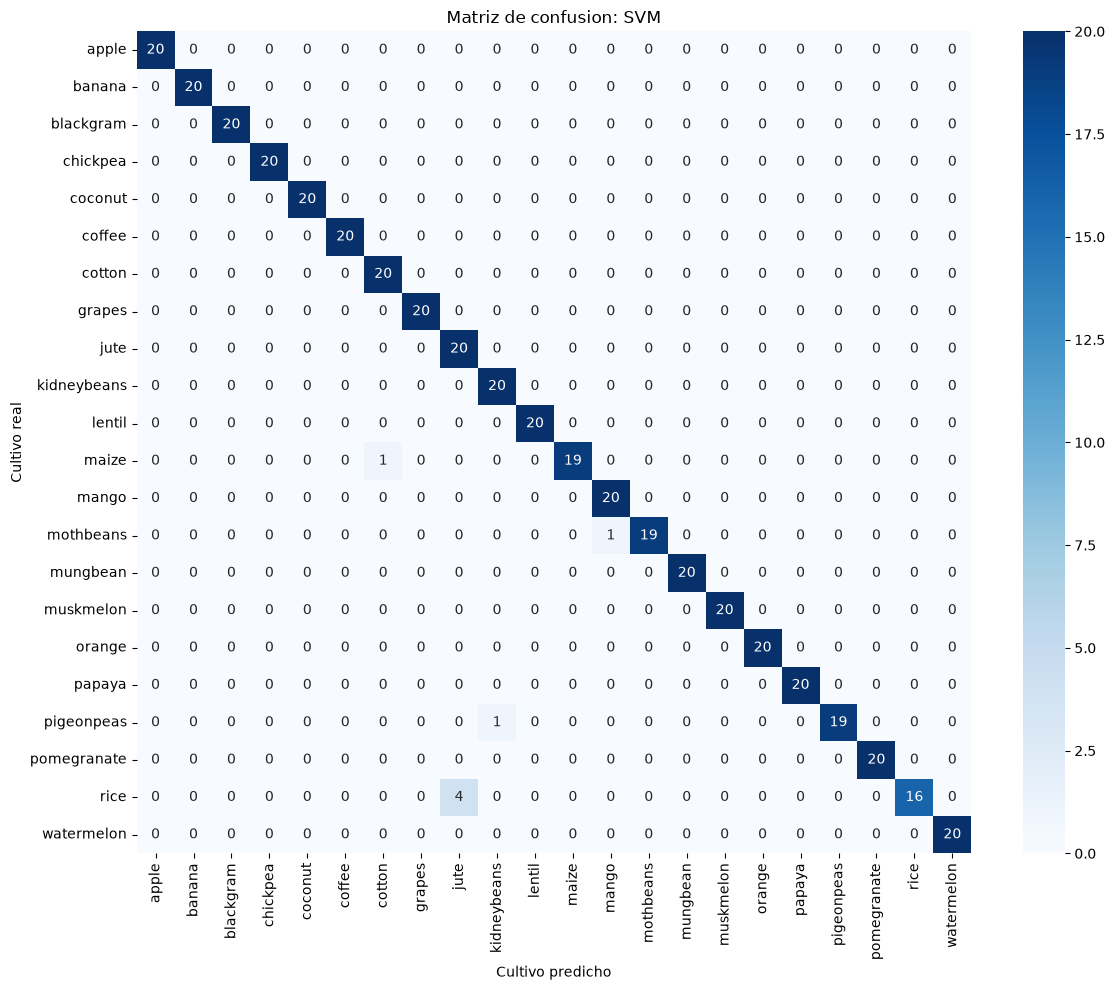

Guardada en: reports\figures\matriz_confusion_svm.png


In [20]:
figures_dir.mkdir(parents=True, exist_ok=True)

for nombre, y_pred in predicciones.items():
    matriz = confusion_matrix(y_test, y_pred)
    figura, eje = plt.subplots(figsize=(12, 10))
    sns.heatmap(
        matriz,
        cmap="Blues",
        annot=True,
        fmt="d",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=eje,
    )
    eje.set_title(f"Matriz de confusion: {nombre}")
    eje.set_xlabel("Cultivo predicho")
    eje.set_ylabel("Cultivo real")
    eje.tick_params(axis="x", labelrotation=90)
    figura.tight_layout()
    ruta = figures_dir / f"matriz_confusion_{nombre.lower().replace(' ', '_')}.png"
    figura.savefig(ruta, dpi=120)
    plt.show()
    plt.close(figura)
    print(f"Guardada en: {ruta.relative_to(project_root)}")

## 9. Guardar los modelos y resultados

Guardaremos los modelos entrenados con `joblib`. Tambien se guarda el `LabelEncoder`, necesario para traducir las clases numericas que predice el modelo a nombres de cultivos.

El escalador de SVM forma parte de su `Pipeline`, asi que al guardar ese objeto se conserva el preprocesamiento junto al clasificador. Esto evita aplicar accidentalmente un escalador distinto cuando usemos el modelo mas adelante.

Modelo guardado: models\random_forest.pkl
Modelo guardado: models\xgboost.pkl
Modelo guardado: models\svm.pkl
Codificador guardado: models\label_encoder.pkl
Metricas guardadas: reports\comparacion_modelos.csv


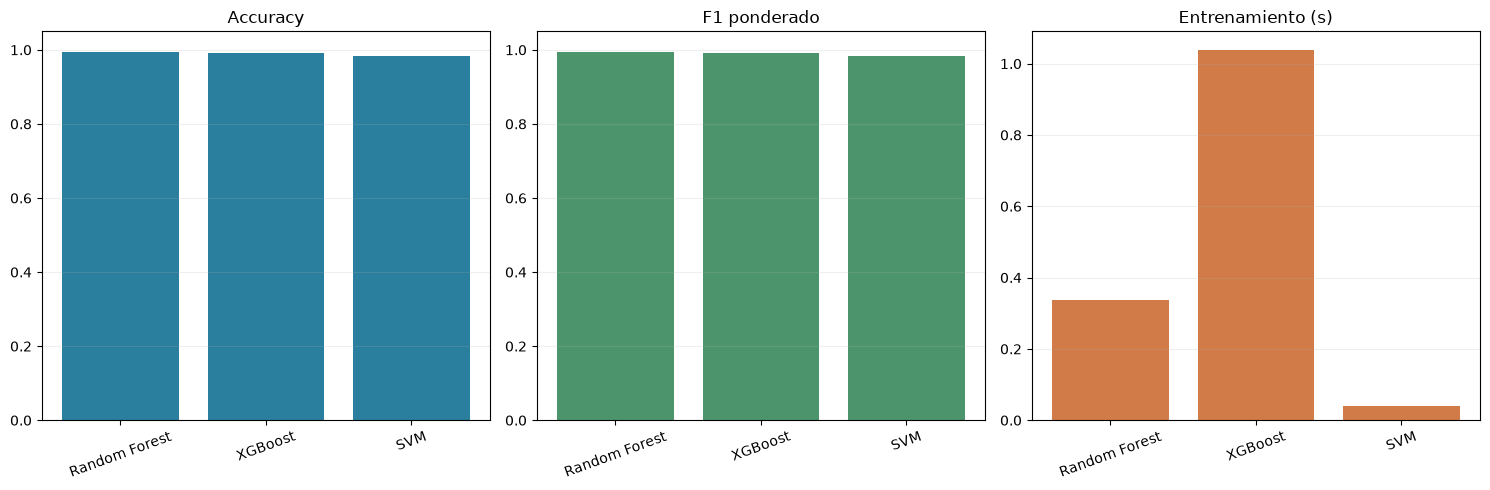

In [21]:
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

for nombre, modelo in modelos.items():
    nombre_archivo = nombre.lower().replace(" ", "_")
    ruta_modelo = models_dir / f"{nombre_archivo}.pkl"
    joblib.dump(modelo, ruta_modelo)
    print(f"Modelo guardado: {ruta_modelo.relative_to(project_root)}")

label_encoder_path = models_dir / "label_encoder.pkl"
joblib.dump(label_encoder, label_encoder_path)
print(f"Codificador guardado: {label_encoder_path.relative_to(project_root)}")

comparison_path = reports_dir / "comparacion_modelos.csv"
resultados_df.to_csv(comparison_path, index=False)
print(f"Metricas guardadas: {comparison_path.relative_to(project_root)}")

# Guardamos tambien el grafico comparativo para incluirlo en los materiales de clase.
figura, ejes = plt.subplots(1, 3, figsize=(15, 5))
for eje, (columna, titulo, color) in zip(
    ejes,
    [
        ("accuracy", "Accuracy", "#2a7f9e"),
        ("f1_weighted", "F1 ponderado", "#4c956c"),
        ("tiempo_entrenamiento_s", "Entrenamiento (s)", "#d17b49"),
    ],
):
    eje.bar(resultados_df["modelo"], resultados_df[columna], color=color)
    eje.set_title(titulo)
    eje.tick_params(axis="x", labelrotation=20)
    if columna != "tiempo_entrenamiento_s":
        eje.set_ylim(0, 1.05)
    eje.grid(axis="y", alpha=0.2)

figura.tight_layout()
comparison_figure_path = figures_dir / "comparacion_modelos.png"
figura.savefig(comparison_figure_path, dpi=120)
plt.show()
plt.close(figura)

## 10. Cargar un modelo y predecir

Para usar el modelo en otra sesion, cargamos el archivo `.pkl`. La prediccion es un numero porque entrenamos con etiquetas codificadas; `inverse_transform` la convierte otra vez al nombre original.

La fila de ejemplo conserva las mismas columnas y el mismo orden que usamos durante el entrenamiento. En un sistema real, tambien verificariamos que nuevas mediciones tengan unidades y rangos coherentes.

In [22]:
modelo_cargado = joblib.load(models_dir / "random_forest.pkl")
codificador_cargado = joblib.load(models_dir / "label_encoder.pkl")

muestra = X_test.iloc[[0]]
prediccion_codificada = modelo_cargado.predict(muestra)
prediccion_cultivo = codificador_cargado.inverse_transform(prediccion_codificada)
cultivo_real = codificador_cargado.inverse_transform([y_test.iloc[0]])

print(f"Cultivo real: {cultivo_real[0]}")
print(f"Cultivo predicho: {prediccion_cultivo[0]}")

Cultivo real: orange
Cultivo predicho: orange


## Cierre de la clase

En esta practica entrenamos tres clasificadores para recomendar cultivos, usamos una prueba comun para compararlos, interpretamos la importancia global de las variables y guardamos los modelos y resultados. La importancia ayuda a formular preguntas de negocio, pero no demuestra causalidad. El siguiente paso del pipeline sera analizar errores y validar las decisiones con datos y conocimiento del dominio.